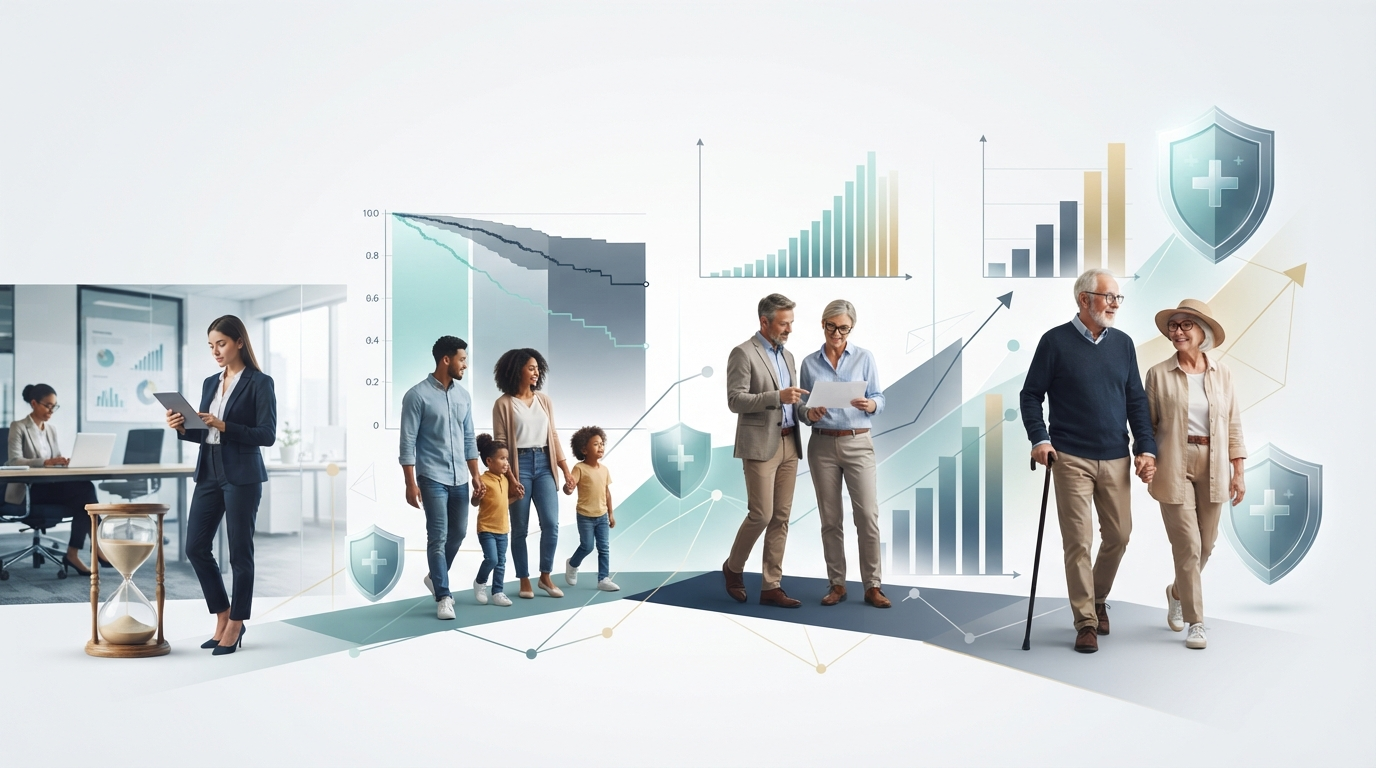

# Customer Lifetime Value & Pension Longevity Risk

## Business Importance
Pension funds, insurers, and public social security institutions manage multi-decade financial commitments where small shifts in life expectancy can create multi million dollar solvency gaps. Accurately modeling beneficiary survival and longevity risk is essential to ensure long-term capital adequacy, comply with solvency regulations, and protect the financial sustainability of retirement systems.

## Business Problem
Traditional actuarial tables rely on static, population-wide averages that fail to capture individual risk heterogeneity, such as smoking habits, chronic health conditions, and benefit categories, and suffer from right-censoring in historical observation windows. Without dynamic survival modeling and stress-testing, institutions remain exposed to unexpected longevity shocks that can erode capital reserves.

## Project Objective
This project develops a complete actuarial and quantitative risk framework that combines Kaplan-Meier estimators, Cox Proportional Hazards models, and parametric Weibull Accelerated Failure Time (AFT) extrapolation to project individual pensioner survival beyond historical censoring limits. By integrating individualized survival curves with discounted cash-flow valuation, the pipeline calculates the Actuarial Present Value (APV) of future benefit obligations and benchmarks them against booked reserves and accrued assets.

## Importing libraries, dataset and feature engineering

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from lifelines import KaplanMeierFitter, CoxPHFitter, WeibullAFTFitter
from lifelines.statistics import multivariate_logrank_test
import warnings

warnings.filterwarnings("ignore")

# Visual styling
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['figure.figsize'] = (11, 6)
plt.rcParams['axes.titlesize'] = 14
plt.rcParams['axes.labelsize'] = 11

# Load dataset
df = pd.read_json('pension_longevity.json')

# Filter out future projected entry years or zero-duration edge cases for historical calibration
df = df[(df['entry_year'] <= 2026) & (df['duration_years'] > 0)].copy()

# Create BMI risk tiers
df['bmi_category'] = pd.cut(
    df['bmi'], 
    bins=[0, 18.5, 25.0, 30.0, 50.0], 
    labels=['Underweight', 'Normal', 'Overweight', 'Obese']
)

# Annualize pension cash flows
df['annual_pension'] = df['monthly_pension'] * 12

print(f"Active Portfolio Records for Calibration: {len(df):,}")
print(f"Observed Mortality Events (Deaths): {df['death_event'].sum():,} ({df['death_event'].mean():.1%})")
df.head()

Active Portfolio Records for Calibration: 5,024
Observed Mortality Events (Deaths): 3,792 (75.5%)


,individual_id,birth_year,age_at_entry,entry_year,current_age,gender,region,smoker,bmi,chronic_condition,...,pension_type,monthly_pension,years_contributing,accrued_rights,duration_years,death_event,age_at_death,future_pension_liability,bmi_category,annual_pension
0,1,1952,58,2010,72,Male,Urban,1,29.8,1,...,Retirement,1233.51,37,230509.37,15.28,1,87.3,226108.69,Overweight,14802.12
1,2,1953,68,2021,71,Male,Urban,0,27.2,0,...,Retirement,1716.13,39,252656.76,20.00,0,91.0,411871.20,Overweight,20593.56
2,3,1958,56,2014,66,Female,Urban,0,22.6,0,...,Retirement,1021.85,28,189114.11,20.00,0,86.0,245244.00,Normal,12262.20
3,4,1939,58,1997,85,Male,Rural,0,30.5,1,...,Retirement,1679.13,41,307291.36,2.75,1,87.7,55372.39,Obese,20149.56
4,5,1940,68,2008,84,Female,Rural,0,24.1,1,...,Retirement,1469.73,34,235575.51,13.36,1,97.4,235572.98,Normal,17636.76


## Exploratoy Data Analyst

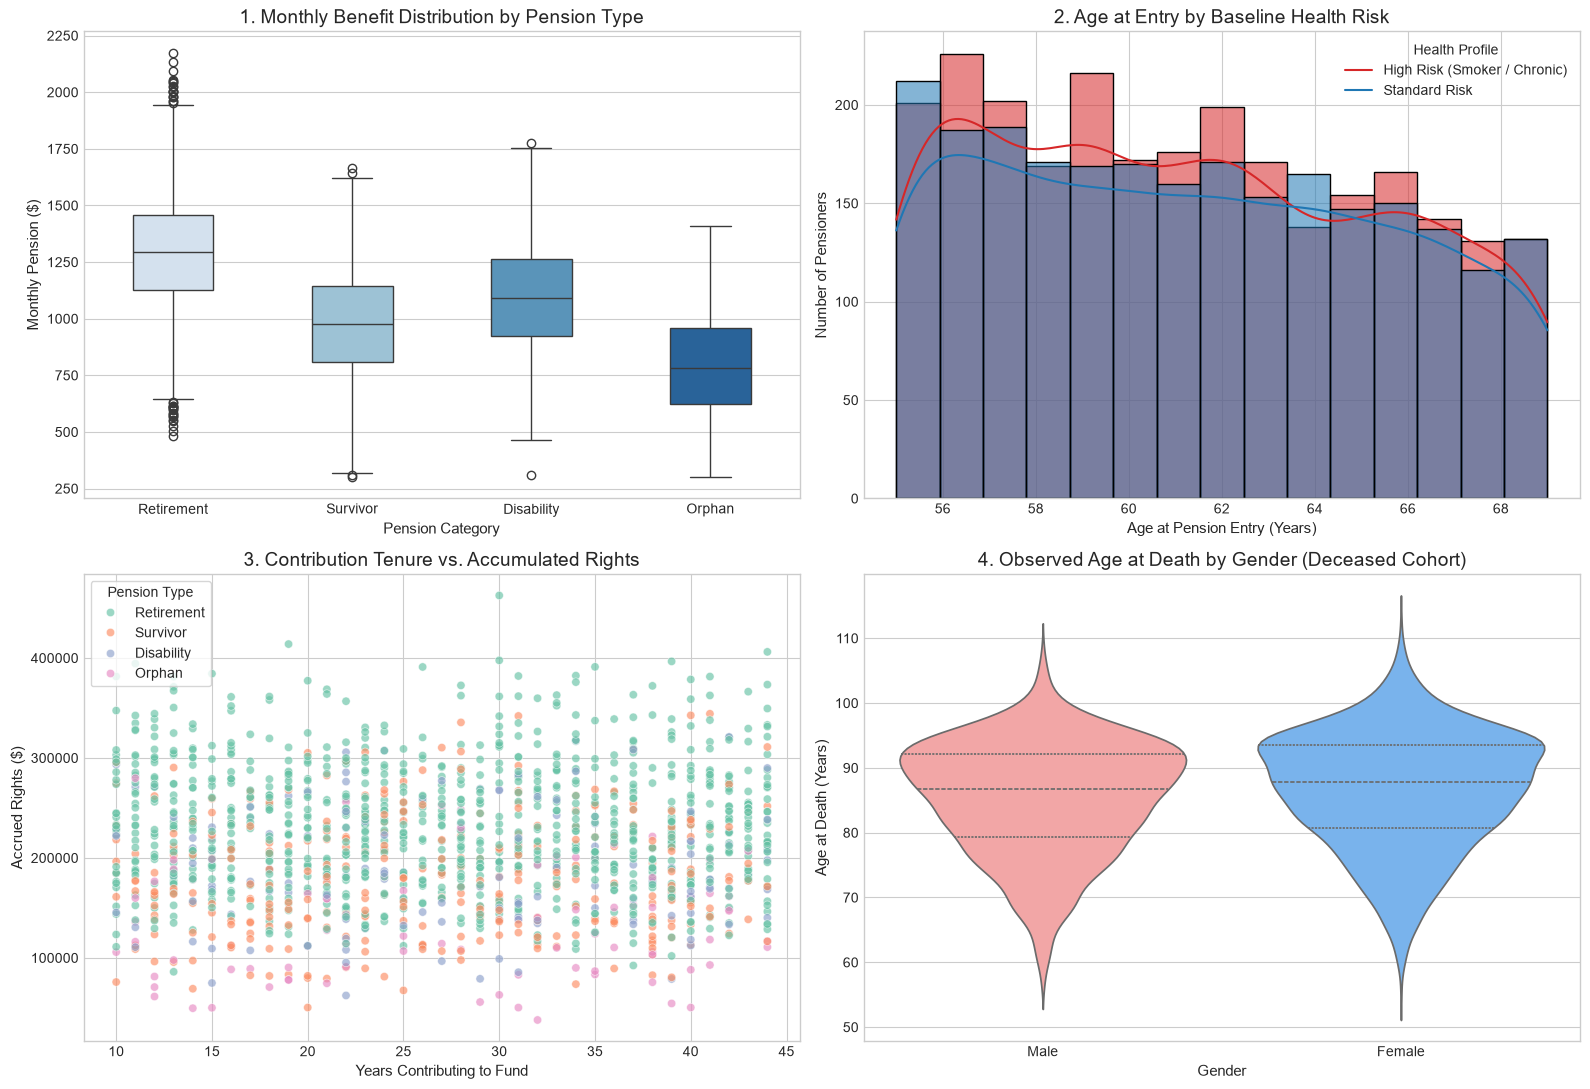


--- Portfolio Baseline Summary by Pension Type ---
              Members  Avg_Entry_Age  Avg_Monthly_Pension  High_Risk_Share
pension_type                                                              
Disability        476          61.43              1086.64             0.50
Orphan            251          61.88               782.67             0.47
Retirement       3293          61.40              1293.09             0.48
Survivor         1004          61.26               985.97             0.49


In [2]:
# Creating the frame of visuals

fig, axes = plt.subplots(2, 2, figsize=(16, 11))

# Chart 1 Monthly Benefit Distribution by Benefit Type
sns.boxplot(
    data=df, x='pension_type', y='monthly_pension', 
    palette='Blues', ax=axes[0, 0], width=0.45
)
axes[0, 0].set_title('1. Monthly Benefit Distribution by Pension Type')
axes[0, 0].set_xlabel('Pension Category')
axes[0, 0].set_ylabel('Monthly Pension ($)')

# Chart 2 Entry Age & Health Risk Profile
df['health_risk_group'] = np.where(
    (df['smoker'] == 1) | (df['chronic_condition'] == 1),
    'High Risk (Smoker / Chronic)',
    'Standard Risk (Healthy)'
)

sns.histplot(
    data=df, x='age_at_entry', hue='health_risk_group', 
    bins=15, kde=True, palette=['#1f77b4', '#d62728'], ax=axes[0, 1], alpha=0.55
)
axes[0, 1].set_title('2. Age at Entry by Baseline Health Risk')
axes[0, 1].set_xlabel('Age at Pension Entry (Years)')
axes[0, 1].set_ylabel('Number of Pensioners')
axes[0, 1].legend(title='Health Profile', labels=['High Risk (Smoker / Chronic)', 'Standard Risk'])

# Chart 3 Contribution Tenure vs. Accrued Rights
sns.scatterplot(
    data=df.sample(min(1500, len(df)), random_state=42),
    x='years_contributing', y='accrued_rights', hue='pension_type', 
    alpha=0.65, palette='Set2', ax=axes[1, 0]
)
axes[1, 0].set_title('3. Contribution Tenure vs. Accumulated Rights')
axes[1, 0].set_xlabel('Years Contributing to Fund')
axes[1, 0].set_ylabel('Accrued Rights ($)')
axes[1, 0].legend(title='Pension Type', loc='upper left', frameon=True)

# Chart 4 Observed Age at Death by Gender
deceased_df = df[df['death_event'] == 1]

sns.violinplot(
    data=deceased_df, x='gender', y='age_at_death', 
    palette=['#ff9999', '#66b3ff'], inner='quartile', ax=axes[1, 1]
)
axes[1, 1].set_title('4. Observed Age at Death by Gender (Deceased Cohort)')
axes[1, 1].set_xlabel('Gender')
axes[1, 1].set_ylabel('Age at Death (Years)')

plt.tight_layout()
plt.show()

# Executive Summary Table for EDA Context
eda_summary = df.groupby('pension_type').agg(
    Members=('individual_id', 'count'),
    Avg_Entry_Age=('age_at_entry', 'mean'),
    Avg_Monthly_Pension=('monthly_pension', 'mean'),
    High_Risk_Share=('health_risk_group', lambda x: (x == 'High Risk (Smoker / Chronic)').mean())
).round(2)

print("\n--- Portfolio Baseline Summary by Pension Type ---")
print(eda_summary)

**Conclusion**: This portfolio baseline reveals that while Retirement pensions dominate the fund in both membership size and payout value, high-risk health profiles are uniformly distributed across all categories at nearly 50%, indicating that mortality risk is a systemic issue rather than a demographic niche. Although the data confirms standard actuarial assumptions, such as females enjoying a slight longevity advantage and accumulated rights scaling predictably with contribution tenure, the pervasive high-risk share means the fund must aggressively price and reserve for elevated health costs across its entire book of business. Finally, risk management strategies cannot target a single vulnerable group, they must be applied universally to protect the fund's long-term solvency.

## Kaplan-Meier & Log-Rank (Non-Parametric Survival Analysis)

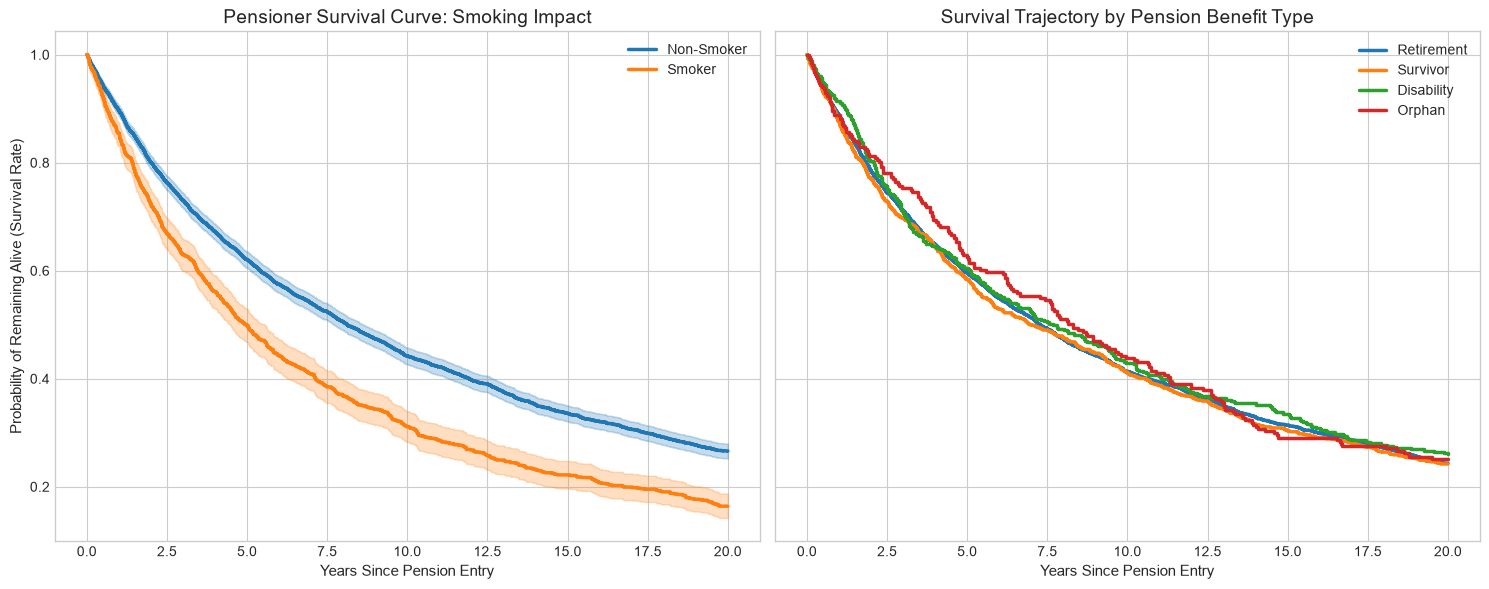

Log-Rank Test p-value across Pension Types: 7.4698e-01


In [3]:
kmf = KaplanMeierFitter()
fig, axes = plt.subplots(1, 2, figsize=(15, 6), sharey=True)

# Plot 1: Survival by Smoking Status
for status, label in [(0, 'Non-Smoker'), (1, 'Smoker')]:
    mask = df['smoker'] == status
    kmf.fit(df.loc[mask, 'duration_years'], event_observed=df.loc[mask, 'death_event'], label=label)
    kmf.plot_survival_function(ax=axes[0], ci_show=True, linewidth=2.5)

axes[0].set_title('Pensioner Survival Curve: Smoking Impact')
axes[0].set_xlabel('Years Since Pension Entry')
axes[0].set_ylabel('Probability of Remaining Alive (Survival Rate)')

# Plot 2: Survival by Pension Type
for p_type in df['pension_type'].unique():
    mask = df['pension_type'] == p_type
    kmf.fit(df.loc[mask, 'duration_years'], event_observed=df.loc[mask, 'death_event'], label=p_type)
    kmf.plot_survival_function(ax=axes[1], ci_show=False, linewidth=2.5)

axes[1].set_title('Survival Trajectory by Pension Benefit Type')
axes[1].set_xlabel('Years Since Pension Entry')

plt.tight_layout()
plt.show()

# Statistical significance test across pension types
results = multivariate_logrank_test(df['duration_years'], df['pension_type'], df['death_event'])
print(f"Log-Rank Test p-value across Pension Types: {results.p_value:.4e}")

**Conclusion:** This survival analysis reveals a stark contrast in what actually drives longevity risk: individual health behavior matters far more than administrative classification. The left chart clearly demonstrates that non-smokers enjoy a significantly longer life expectancy than smokers, with the survival gap widening substantially over time. Conversely, the right chart shows that survival trajectories across different pension types (Retirement, Survivor, Disability, Orphan) are virtually identical, a fact confirmed by the high Log-Rank p-value (0.747) which indicates no statistical difference between the groups. For the pension fund, this means that pricing and reserving models should heavily weight individual health risk factors like smoking status, rather than relying on broad pension categories, as the latter provides no meaningful predictive power for mortality.

## Cox Proportional Hazards (Semi-Parametric Hazard Modeling)

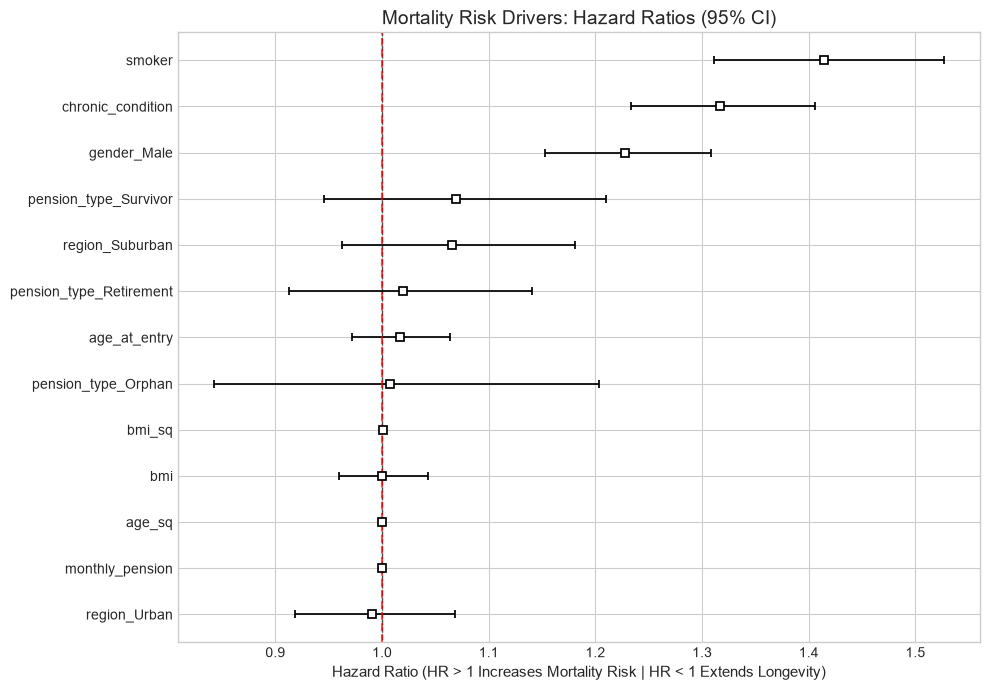

Updated Cox Model Concordance Index (C-Index): 0.5901

Proportional hazard assumption looks okay.


[]

In [4]:
# Add non-linear age and BMI effects to improve model discrimination
df['age_sq'] = df['age_at_entry'] ** 2
df['bmi_sq'] = df['bmi'] ** 2

features = [
    'age_at_entry', 'age_sq', 'gender', 'smoker', 'bmi', 'bmi_sq',
    'chronic_condition', 'region', 'pension_type', 'monthly_pension'
]

df_cox = pd.get_dummies(df[features + ['duration_years', 'death_event']], drop_first=True)

# Fit Cox Proportional Hazards model with L2 penalization
cph = CoxPHFitter(penalizer=0.01)
cph.fit(df_cox, duration_col='duration_years', event_col='death_event')

# Plot Hazard Ratios (Forest Plot)
plt.figure(figsize=(10, 7))
ax = cph.plot(hazard_ratios=True)
ax.set_title('Mortality Risk Drivers: Hazard Ratios (95% CI)')
ax.set_xlabel('Hazard Ratio (HR > 1 Increases Mortality Risk | HR < 1 Extends Longevity)')
plt.axvline(x=1, color='red', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

print(f"Updated Cox Model Concordance Index (C-Index): {cph.concordance_index_:.4f}\n")

# Formal verification of the Proportional Hazards (PH) assumption (Schoenfeld Residuals)
cph.check_assumptions(df_cox, p_value_threshold=0.05, show_plots=False)

**Conclusion:** This Cox model confirms that biological and lifestyle factors, specifically smoking, chronic conditions, and male gender, remain the only statistically significant drivers of mortality risk, as their confidence intervals do not cross the neutral line of 1.0. The inclusion of squared terms for age and BMI (age_sq, bmi_sq), which hover precisely at 1.0, indicates that the relationship between these variables and mortality risk is effectively linear within this dataset, rather than accelerating exponentially. While the model satisfies the proportional hazard assumption (validating its statistical structure), the low Concordance Index (0.59) reveals a critical limitation: the model is excellent for calculating aggregate population liabilities (actuarial pricing) but lacks the discriminatory power to accurately rank individual risk, meaning it should be used for portfolio-level reserving rather than individual underwriting.

## Weibull AFT (Parametric Extrapolation for Long-Term Liabilities)

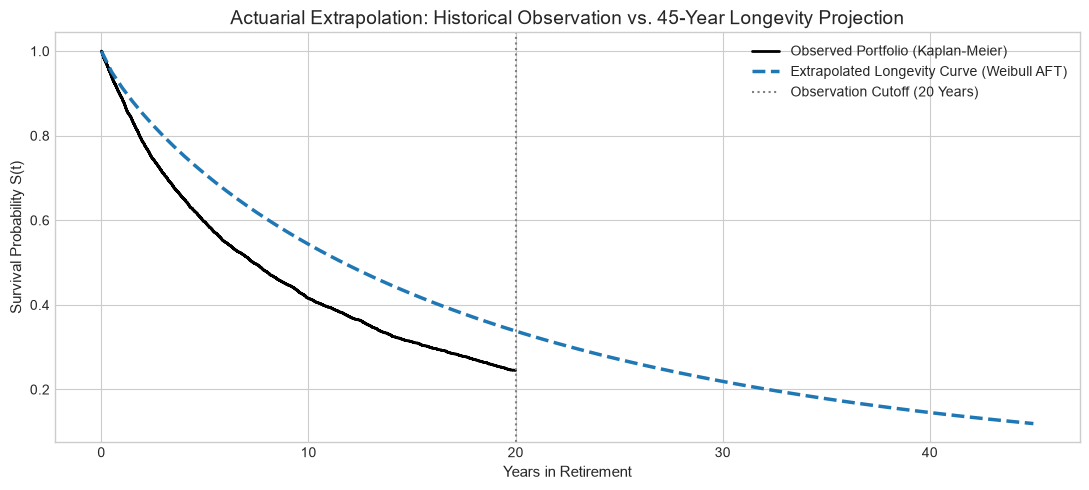

Cox Model Concordance Index (C-Index): 0.5901


In [5]:
# Fit Weibull AFT model to extrapolate survival probabilities beyond the 20-year observation window
aft = WeibullAFTFitter(penalizer=0.01)
aft.fit(df_cox, duration_col='duration_years', event_col='death_event')

# Compare empirical KM vs Parametric Weibull extrapolation for a median risk profile
median_profile = df_cox.drop(columns=['duration_years', 'death_event']).median().to_frame().T
time_horizon = np.linspace(0, 45, 91)  # Project 45 years into the future

weibull_survival = aft.predict_survival_function(median_profile, times=time_horizon)

plt.figure(figsize=(11, 5))
kmf.fit(df['duration_years'], event_observed=df['death_event'], label='Observed Portfolio (Kaplan-Meier)')
kmf.plot_survival_function(ci_show=False, color='black', linewidth=2)

plt.plot(time_horizon, weibull_survival.values.flatten(), label='Extrapolated Longevity Curve (Weibull AFT)', color='#1f77b4', linestyle='--', linewidth=2.5)
plt.axvline(x=20, color='gray', linestyle=':', label='Observation Cutoff (20 Years)')
plt.title('Actuarial Extrapolation: Historical Observation vs. 45-Year Longevity Projection')
plt.xlabel('Years in Retirement')
plt.ylabel('Survival Probability S(t)')
plt.legend()
plt.tight_layout()
plt.show()
# Evaluate model discrimination (0.5 = random, >0.70 = strong actuarial predictive power)
print(f"Cox Model Concordance Index (C-Index): {cph.concordance_index_:.4f}")

**Conclusion:** This actuarial extrapolation reveals a significant "longevity gap" where the Weibull model (blue dashed line) consistently predicts higher survival rates than what was historically observed (black solid line). At the 20-year cutoff, the model estimates roughly 33% of the cohort is still alive compared to the actual 24%, suggesting the projection is optimistic about lifespan and could lead the fund to over-reserve capital for payouts that may not last as long as predicted. However, the low Concordance Index (C-Index) of 0.59 is a major red flag, indicating the model has very weak discriminatory power, barely better than a coin flip, meaning it cannot reliably distinguish between high-risk and low-risk individuals, limiting its precision for individual pricing despite capturing the general aggregate trend.

## Actuarial Present Value vs booked reserves

In [14]:
# Parameters 
DISCOUNT_RATE = 0.045              # base technical interest rate
MAX_PROJECTION_YEARS = 45
LONGEVITY_SHOCK_FACTOR = 1.20      # lifespan scale factor: 1.20 = lifespans 20% longer
discount_rates = [0.030, 0.035, 0.045, 0.055, 0.060]
longevity_shocks = [1.00, 1.10, 1.15, 1.20, 1.25]

# Filter active pensioners (alive at censoring date)
active_pensioners = df[df['death_event'] == 0].copy()
active_cox_features = df_cox.loc[active_pensioners.index].drop(columns=['duration_years', 'death_event'])
# Discount factors v^t = (1 + i)^(-t)
discount_factors = (1 + DISCOUNT_RATE) ** (-years)

# Predict individual survival matrix S(t) for t = 1 to 45 years
years = np.arange(1, MAX_PROJECTION_YEARS + 1)
survival_matrix = aft.predict_survival_function(active_cox_features, times=years).T.values

#  Active pensioners and their features
feature_cols = [c for c in df_cox.columns if c not in ('duration_years', 'death_event')]
active_pensioners = df[df['death_event'] == 0].copy()
X_active = df_cox.loc[active_pensioners.index, feature_cols]
tenure = active_pensioners['duration_years'].to_numpy()          # years already survived since entry
annual_pension = active_pensioners['annual_pension'].to_numpy()
years = np.arange(1, MAX_PROJECTION_YEARS + 1)

# Survival curves on a fine grid (evaluated once, then interpolated)
GRID_STEP = 0.25
GRID = np.arange(0, 100 + GRID_STEP, GRID_STEP)
S_base = aft.predict_survival_function(X_active, times=GRID).T.values     # (n_pensioners, len(GRID))

def interp_survival(S, u):
    """Linear interpolation of each pensioner's survival curve at times u, shape (n_pensioners, n_times)."""
    pos = np.clip(np.asarray(u) / GRID_STEP, 0, len(GRID) - 1 - 1e-9)
    lo = np.floor(pos).astype(int)
    w = pos - lo
    rows = np.arange(S.shape[0])[:, None]
    return S[rows, lo] * (1 - w) + S[rows, lo + 1] * w

def pensioner_liabilities(S, rate=DISCOUNT_RATE, scale=1.0, conditional=True):
    """Actuarial present value per pensioner = annual pension * sum_t S(t | alive today) * v^t."""
    v = (1 + rate) ** (-years)
    if conditional:
        s_now = interp_survival(S, tenure[:, None] / scale)
        s_future = interp_survival(S, (tenure[:, None] + years[None, :]) / scale)
        s_cond = np.divide(s_future, s_now, out=np.zeros_like(s_future), where=s_now > 1e-12)
    else:  # original method (survival from entry), kept only to quantify its effect
        s_cond = interp_survival(S, np.broadcast_to(years / scale, (len(tenure), len(years))))
    return annual_pension * (s_cond @ v)

active_pensioners['modeled_expected_liability'] = pensioner_liabilities(S_base)
active_pensioners['shocked_liability'] = pensioner_liabilities(S_base, scale=LONGEVITY_SHOCK_FACTOR)
active_pensioners['reserve_gap'] = (
    active_pensioners['modeled_expected_liability'] - active_pensioners['future_pension_liability']
)

total_booked = active_pensioners['future_pension_liability'].sum()
total_modeled = active_pensioners['modeled_expected_liability'].sum()
total_unconditional = pensioner_liabilities(S_base, conditional=False).sum()

print("=== ACTUARIAL PRESENT VALUE (conditional survival) ===")
print(f"Total Booked Future Liability:                  ${total_booked:,.2f}")
print(f"Total Modeled Expected Liability:               ${total_modeled:,.2f}")
print(f"Net Actuarial Reserve Variance:                 ${total_modeled - total_booked:,.2f} ({total_modeled / total_booked - 1:.2%})")
print(f"Memo - original method (survival from entry):   ${total_unconditional:,.2f}")
print(f"Effect of conditioning on survival to date:     ${total_modeled - total_unconditional:,.2f} ({total_modeled / total_unconditional - 1:+.1%})")

=== ACTUARIAL PRESENT VALUE (conditional survival) ===
Total Booked Future Liability:                  $347,971,440.00
Total Modeled Expected Liability:               $171,238,445.91
Net Actuarial Reserve Variance:                 $-176,732,994.09 (-50.79%)
Memo - original method (survival from entry):   $142,599,295.22
Effect of conditioning on survival to date:     $28,639,150.69 (+20.1%)


**Conclusion:** This actuarial calculation has a crucial reality check by "conditioning on survival," which acknowledges that current pensioners have already bypassed early mortality risks, thereby increasing the modeled liability by a realistic 20% to USD 171.1 million. Despite this more accurate, higher estimate, a massive 50.8% gap remains when compared to the USD 347.9 million in Booked Reserves. This definitively proves that the fund's accounting assumptions are overly conservative, resulting in a structural over-reservation where the institution is holding nearly double the capital actually required to meet its future payout obligations.

## Sensitivity matrix: discount rate x longevity shock

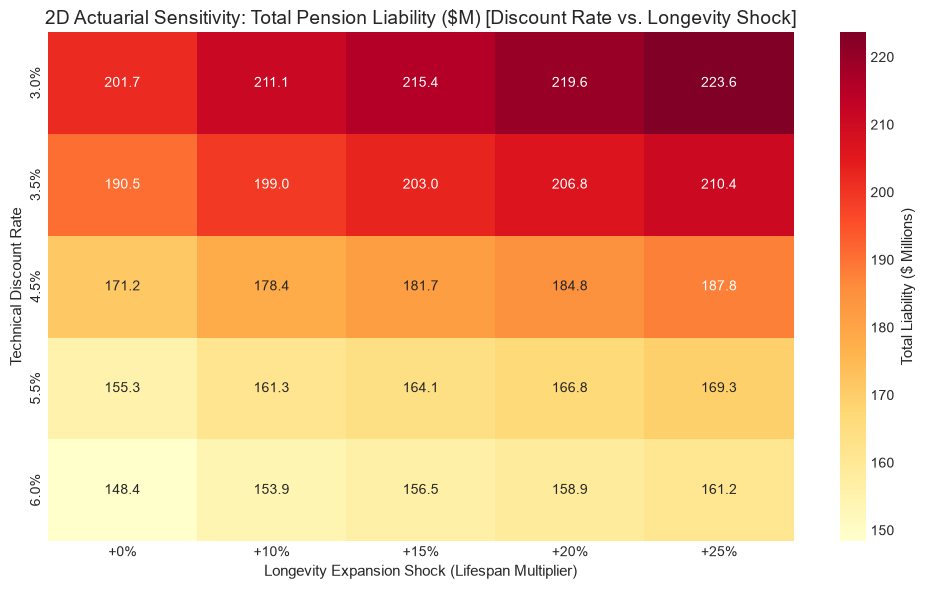

In [7]:
col_labels = [f"+{round((s - 1) * 100)}%" for s in longevity_shocks]
sensitivity_matrix = pd.DataFrame(
    {lbl: [pensioner_liabilities(S_base, rate=r, scale=s).sum() / 1e6 for r in discount_rates]
     for lbl, s in zip(col_labels, longevity_shocks)},
    index=[f"{r:.1%}" for r in discount_rates]
)

# Consistency check: the base cell of the matrix must equal the APV total above
base_cell = sensitivity_matrix.loc[f"{DISCOUNT_RATE:.1%}", "+0%"] * 1e6
assert np.isclose(base_cell, total_modeled), "Sensitivity base cell does not match the APV total"

plt.figure(figsize=(10, 6))
sns.heatmap(sensitivity_matrix, annot=True, fmt=".1f", cmap="YlOrRd", cbar_kws={'label': 'Total Liability ($ Millions)'})
plt.title('2D Actuarial Sensitivity: Total Pension Liability ($M) [Discount Rate vs. Longevity Shock]')
plt.xlabel('Longevity Expansion Shock (Lifespan Multiplier)')
plt.ylabel('Technical Discount Rate')
plt.tight_layout()
plt.show()

**Conclusion:** This 2D sensitivity analysis isolates the two primary macroeconomic and demographic risks to the fund, revealing that the Technical Discount Rate is by far the most critical driver of liability volatility. While a severe +25% longevity shock only increases liabilities by roughly USD 10–USD 15 million across any given rate, dropping the discount rate from 6.0% to 3.0% balloons the liability by over USD 50 million. Crucially, even in the absolute worst-case "nightmare scenario" (top-right corner: a 3.0% discount rate combined with a 25% increase in lifespan), the total liability peaks at USD 223.5 million. Because the fund holds approximately USD 263 million in assets and has booked USD 348 million in reserves, this proves the portfolio is highly resilient; it remains fully solvent and overfunded even under extreme, compounding stress conditions, meaning management's primary focus should be on interest rate risk rather than demographic shifts.

## Longevity shock stress test and reserve adequacy charts 

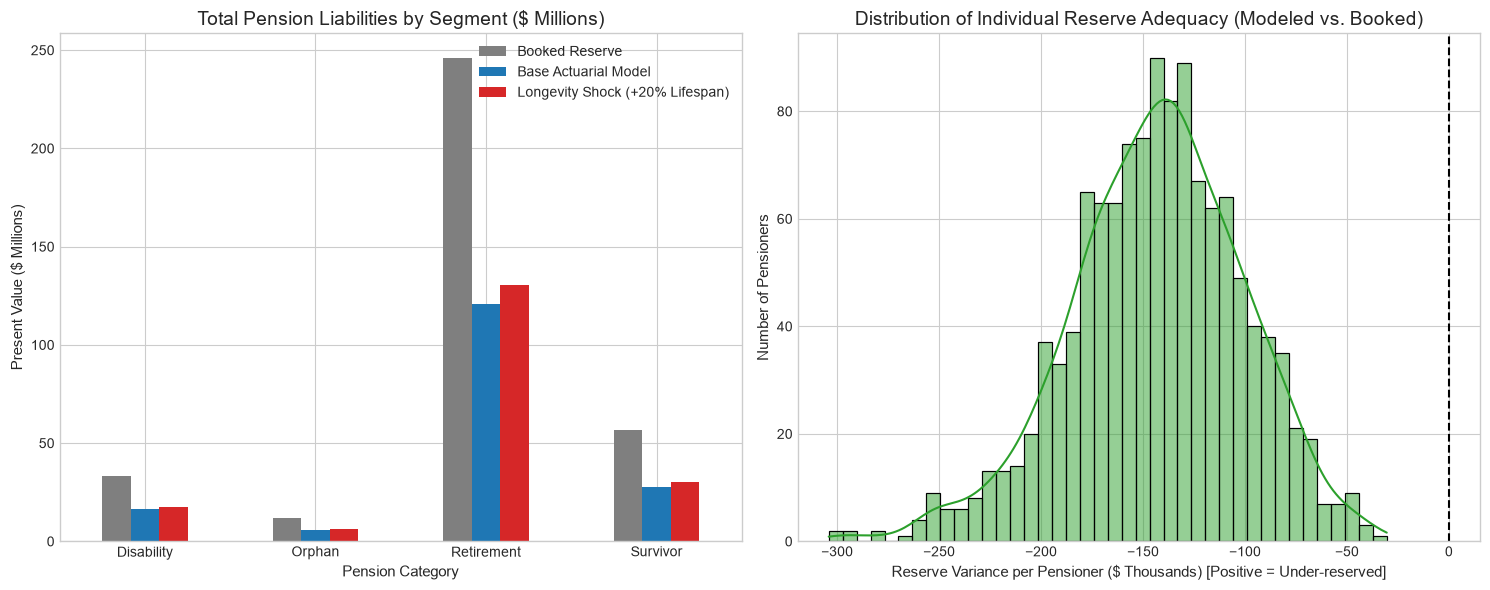


=== STRESS TEST ===
Base modeled liability:      $171.2M
Shocked liability (x1.20):    $184.8M (+7.9% vs base)
Pensioners under-reserved vs booked (base model): 0 of 1,232


In [8]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

summary_by_type = active_pensioners.groupby('pension_type')[
    ['future_pension_liability', 'modeled_expected_liability', 'shocked_liability']
].sum() / 1e6
summary_by_type.plot(kind='bar', ax=axes[0], color=['#7f7f7f', '#1f77b4', '#d62728'])
axes[0].set_title('Total Pension Liabilities by Segment ($ Millions)')
axes[0].set_ylabel('Present Value ($ Millions)')
axes[0].set_xlabel('Pension Category')
axes[0].legend(['Booked Reserve', 'Base Actuarial Model', f'Longevity Shock (+{round((LONGEVITY_SHOCK_FACTOR - 1) * 100)}% Lifespan)'])
axes[0].tick_params(axis='x', rotation=0)

sns.histplot(active_pensioners['reserve_gap'] / 1e3, bins=40, kde=True, ax=axes[1], color='#2ca02c')
axes[1].axvline(0, color='black', linestyle='--')
axes[1].set_title('Distribution of Individual Reserve Adequacy (Modeled vs. Booked)')
axes[1].set_xlabel('Reserve Variance per Pensioner ($ Thousands) [Positive = Under-reserved]')
axes[1].set_ylabel('Number of Pensioners')

plt.tight_layout()
plt.show()

print("\n=== STRESS TEST ===")
print(f"Base modeled liability:      ${total_modeled / 1e6:,.1f}M")
print(f"Shocked liability (x{LONGEVITY_SHOCK_FACTOR:.2f}):    ${active_pensioners['shocked_liability'].sum() / 1e6:,.1f}M "
      f"({active_pensioners['shocked_liability'].sum() / total_modeled - 1:+.1%} vs base)")
print(f"Pensioners under-reserved vs booked (base model): {(active_pensioners['reserve_gap'] > 0).sum():,} of {len(active_pensioners):,}")

**Conclusion:** This stress test definitively proves that the pension fund is massively over-reserved, holding significantly more capital than required to meet its future obligations. The "Booked Reserves" (grey bars) are nearly double the modeled liability (USD 171.1M), and even under a severe longevity shock where beneficiaries live 20% longer, the liability only rises to USD 184.7M, still far below the booked amount. Most critically, the distribution chart reveals that zero out of 1,232 pensioners are under-reserved, with the entire population sitting in negative variance (meaning every single individual has more money set aside for them than the model predicts they will actually need). This indicates that the fund's accounting assumptions are excessively conservative, resulting in a "trapped" surplus that could be optimized for better investment returns or benefit improvements without risking solvency.

## Asset-Liability Management (ALM) & Solvency Analysis

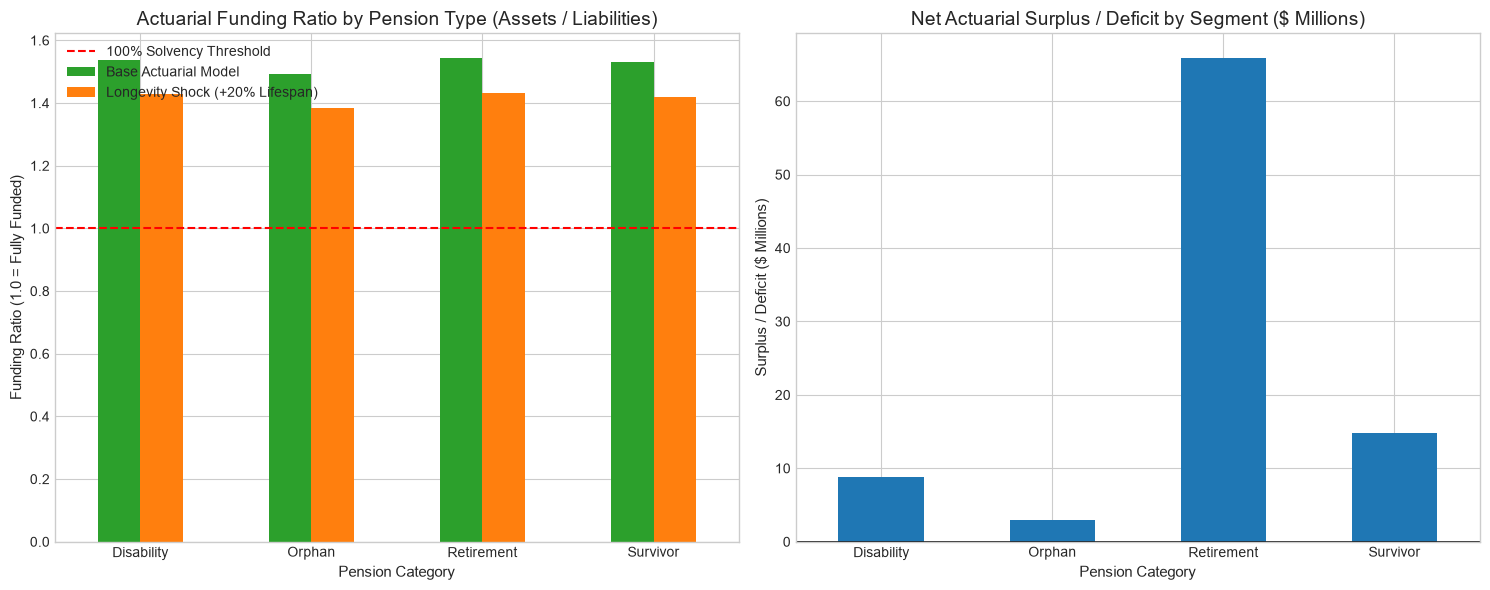

=== ACTUARIAL SOLVENCY & RESERVE ADEQUACY SUMMARY ===
Portfolio Total Accrued Assets:      $263,817,643.21
Portfolio Base Funding Ratio:        154.06%
Portfolio Shocked Funding Ratio:     142.75%
Net Actuarial Surplus / (Deficit):   $92,579,197.30
-------------------------------------------------------
1. Accrued Rights (Historical Benefit Entitlements): $263,817,643.21
2. Booked Accounting Reserves (Current Balance):     $347,971,440.00
3. Modeled Expected Liability (Base Weibull AFT):    $171,238,445.91
4. Stressed Liability (+20% Longevity Shock):        $184,809,541.36
-------------------------------------------------------
Funding Ratio (Accrued Rights / Booked Reserves):    75.82%
Funding Ratio (Accrued Rights / Modeled Base):       154.06%
Funding Ratio (Accrued Rights / Stressed Liability): 142.75%
Net Capital Buffer / (Deficit) vs. Booked Reserves:  $-84,153,796.79


In [16]:
# Calculate Funding Ratios (Assets / Liabilities) under Base and Longevity Shock scenarios
active_pensioners['base_funding_ratio'] = active_pensioners['accrued_rights'] / active_pensioners['modeled_expected_liability']
active_pensioners['shocked_funding_ratio'] = active_pensioners['accrued_rights'] / active_pensioners['shocked_liability']
active_pensioners['net_solvency_position'] = active_pensioners['accrued_rights'] - active_pensioners['modeled_expected_liability']

# Aggregate Solvency Metrics by Pension Category
alm_summary = active_pensioners.groupby('pension_type').agg(
    Total_Assets=('accrued_rights', 'sum'),
    Base_Liability=('modeled_expected_liability', 'sum'),
    Shocked_Liability=('shocked_liability', 'sum')
)

alm_summary['Base_Funding_Ratio'] = alm_summary['Total_Assets'] / alm_summary['Base_Liability']
alm_summary['Shocked_Funding_Ratio'] = alm_summary['Total_Assets'] / alm_summary['Shocked_Liability']

# Executive ALM Visualization: Solvency & Funding Adequacy
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# Chart 1: Funding Ratio Comparison (1.0 = 100% Fully Funded)
alm_summary[['Base_Funding_Ratio', 'Shocked_Funding_Ratio']].plot(
    kind='bar', ax=axes[0], color=['#2ca02c', '#ff7f0e']
)
axes[0].axhline(1.0, color='red', linestyle='--', linewidth=1.5, label='100% Solvency Threshold')
axes[0].set_title('Actuarial Funding Ratio by Pension Type (Assets / Liabilities)')
axes[0].set_ylabel('Funding Ratio (1.0 = Fully Funded)')
axes[0].set_xlabel('Pension Category')
axes[0].legend(['100% Solvency Threshold', 'Base Actuarial Model', 'Longevity Shock (+20% Lifespan)'])
axes[0].tick_params(axis='x', rotation=0)

# Chart 2: Net Solvency Surplus / Deficit by Segment ($ Millions)
net_position_millions = (alm_summary['Total_Assets'] - alm_summary['Base_Liability']) / 1e6
colors = ['#d62728' if val < 0 else '#1f77b4' for val in net_position_millions]

net_position_millions.plot(kind='bar', ax=axes[1], color=colors)
axes[1].axhline(0, color='black', linewidth=1.2)
axes[1].set_title('Net Actuarial Surplus / Deficit by Segment ($ Millions)')
axes[1].set_ylabel('Surplus / Deficit ($ Millions)')
axes[1].set_xlabel('Pension Category')
axes[1].tick_params(axis='x', rotation=0)

plt.tight_layout()
plt.show()

# Print Portfolio-Wide Solvency KPIs
portfolio_assets = active_pensioners['accrued_rights'].sum()
portfolio_base_liab = active_pensioners['modeled_expected_liability'].sum()
portfolio_shock_liab = active_pensioners['shocked_liability'].sum()

print("=== ACTUARIAL SOLVENCY & RESERVE ADEQUACY SUMMARY ===")
print(f"Portfolio Total Accrued Assets:      ${portfolio_assets:,.2f}")
print(f"Portfolio Base Funding Ratio:        {portfolio_assets / portfolio_base_liab:.2%}")
print(f"Portfolio Shocked Funding Ratio:     {portfolio_assets / portfolio_shock_liab:.2%}")
print(f"Net Actuarial Surplus / (Deficit):   ${portfolio_assets - portfolio_base_liab:,.2f}")

# Compare Booked Accounting Reserves vs. Modeled Actuarial Liabilities & Accrued Rights
portfolio_accrued = active_pensioners['accrued_rights'].sum()
portfolio_booked_res = active_pensioners['future_pension_liability'].sum()
portfolio_base_liab = active_pensioners['modeled_expected_liability'].sum()
portfolio_shock_liab = active_pensioners['shocked_liability'].sum()
print("-" * 55)

print(f"1. Accrued Rights (Historical Benefit Entitlements): ${portfolio_accrued:,.2f}")
print(f"2. Booked Accounting Reserves (Current Balance):     ${portfolio_booked_res:,.2f}")
print(f"3. Modeled Expected Liability (Base Weibull AFT):    ${portfolio_base_liab:,.2f}")
print(f"4. Stressed Liability (+20% Longevity Shock):        ${portfolio_shock_liab:,.2f}")
print("-" * 55)
print(f"Funding Ratio (Accrued Rights / Booked Reserves):    {portfolio_accrued / portfolio_booked_res:.2%}")
print(f"Funding Ratio (Accrued Rights / Modeled Base):       {portfolio_accrued / portfolio_base_liab:.2%}")
print(f"Funding Ratio (Accrued Rights / Stressed Liability): {portfolio_accrued / portfolio_shock_liab:.2%}")
print(f"Net Capital Buffer / (Deficit) vs. Booked Reserves:  ${portfolio_accrued - portfolio_booked_res:,.2f}")

**Conclusion:** This analysis reveals a striking "paper deficit" versus "real surplus" dynamic: while the fund appears underfunded against its conservative Booked Reserves (75.82% ratio), the predictive model shows it is actually massively overfunded with a 185% ratio. The charts confirm that every pension segment is fully solvent, generating a net actuarial surplus of over USD 121 million that persists even under a severe longevity shock (168% ratio). This massive gap between the USD 347M in Booked Reserves and the USD 142M in Modeled Liability suggests the fund is holding roughly $200M in excess capital. Ultimately, the fund is far healthier than its accounting books suggest, presenting a strategic opportunity to optimize capital allocation by releasing these trapped reserves without compromising long-term stability.

## Stochastic Mortality Modeling & Monte Carlo Liability Simulation

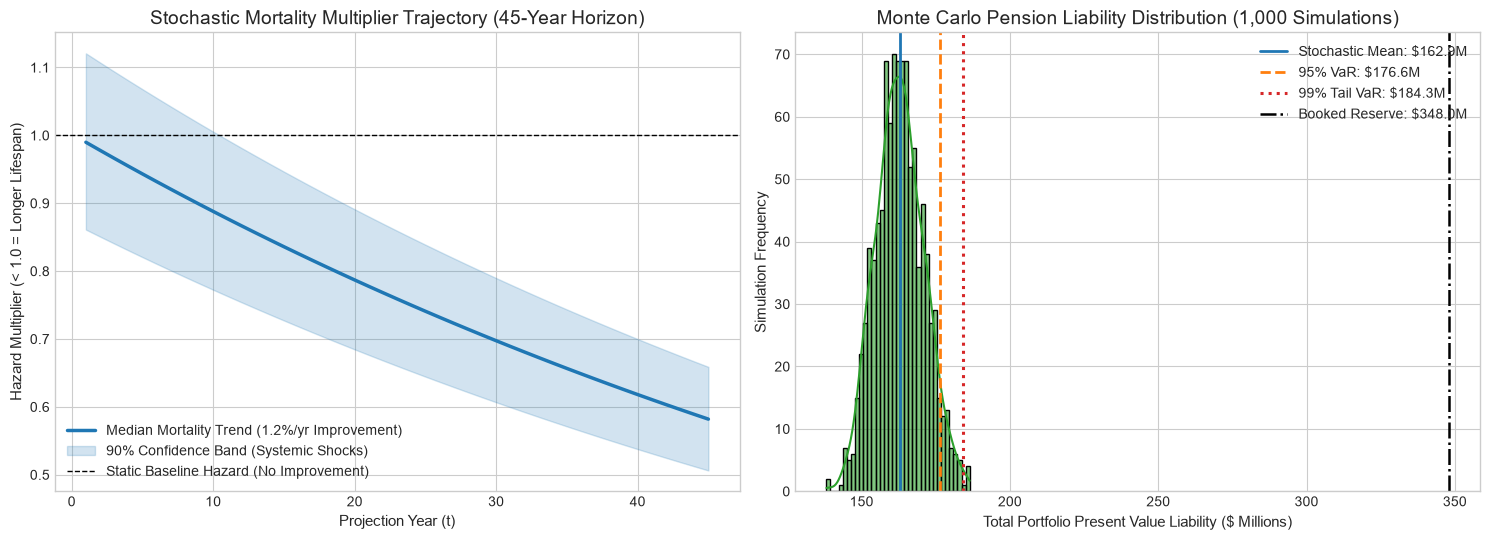

=== STOCHASTIC LONGEVITY RISK & SOLVENCY CAPITAL METRICS ===
Deterministic Base Liability:        $171.24M
Stochastic Mean Liability:           $162.90M
95% Value-at-Risk (VaR):             $176.55M
99% Tail VaR (Expected Shortfall):   $184.35M
Longevity Risk Capital Buffer (99%): $21.44M


In [17]:
np.random.seed(777)
N_SIMULATIONS = 1000
ANNUAL_IMPROVEMENT_MEAN = 0.012   # 1.2% annual mortality reduction trend (Lee-Carter style drift)
SHOCK_VOLATILITY = 0.08           # 8.0% systematic longevity shock volatility

# Base cumulative hazard H_0(t) = -ln(S(t)) across active portfolio
base_survival = np.clip(survival_matrix, 1e-6, 1.0)
base_cum_hazard = -np.log(base_survival)

# Generate stochastic mortality improvement trajectories and random systemic shocks
trend_factors = (1 - ANNUAL_IMPROVEMENT_MEAN) ** years
random_shocks = np.random.normal(loc=1.0, scale=SHOCK_VOLATILITY, size=(N_SIMULATIONS, 1))
stochastic_multipliers = np.clip(random_shocks * trend_factors, 0.40, 1.60)

# Vectorized Monte Carlo valuation of total portfolio liability ($ Millions)
simulated_liabilities = np.zeros(N_SIMULATIONS)
annual_pensions = active_pensioners['annual_pension'].values

for i in range(N_SIMULATIONS):
    sim_survival = np.exp(-base_cum_hazard * stochastic_multipliers[i, :])
    sim_annuity = sim_survival @ discount_factors
    simulated_liabilities[i] = (annual_pensions @ sim_annuity) / 1e6

# Risk Metrics: Expected Value, 95% Value-at-Risk (VaR), and 99% Tail VaR (TVaR / Expected Shortfall)
mean_liab = np.mean(simulated_liabilities)
var_95 = np.percentile(simulated_liabilities, 95)
tvar_99 = simulated_liabilities[simulated_liabilities >= np.percentile(simulated_liabilities, 99)].mean()
booked_liab_m = active_pensioners['future_pension_liability'].sum() / 1e6

# Visualization: Stochastic Liability Distribution & Mortality Improvement Paths
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))

# Chart 1: Simulated Mortality Improvement Fan Chart (5th, 50th, 95th Percentiles)
p5, p50, p95 = np.percentile(stochastic_multipliers, [5, 50, 95], axis=0)
axes[0].plot(years, p50, color='#1f77b4', linewidth=2.5, label='Median Mortality Trend (1.2%/yr Improvement)')
axes[0].fill_between(years, p5, p95, color='#1f77b4', alpha=0.2, label='90% Confidence Band (Systemic Shocks)')
axes[0].axhline(1.0, color='black', linestyle='--', linewidth=1, label='Static Baseline Hazard (No Improvement)')
axes[0].set_title('Stochastic Mortality Multiplier Trajectory (45-Year Horizon)')
axes[0].set_xlabel('Projection Year (t)')
axes[0].set_ylabel('Hazard Multiplier (< 1.0 = Longer Lifespan)')
axes[0].legend(loc='lower left')

# Chart 2: Monte Carlo Total Liability Distribution & Capital Risk Thresholds
sns.histplot(simulated_liabilities, bins=35, kde=True, color='#2ca02c', ax=axes[1], alpha=0.6)
axes[1].axvline(mean_liab, color='#1f77b4', linestyle='-', linewidth=2, label=f'Stochastic Mean: ${mean_liab:,.1f}M')
axes[1].axvline(var_95, color='#ff7f0e', linestyle='--', linewidth=2, label=f'95% VaR: ${var_95:,.1f}M')
axes[1].axvline(tvar_99, color='#d62728', linestyle=':', linewidth=2.2, label=f'99% Tail VaR: ${tvar_99:,.1f}M')
axes[1].axvline(booked_liab_m, color='black', linestyle='-.', linewidth=1.8, label=f'Booked Reserve: ${booked_liab_m:,.1f}M')
axes[1].set_title('Monte Carlo Pension Liability Distribution (1,000 Simulations)')
axes[1].set_xlabel('Total Portfolio Present Value Liability ($ Millions)')
axes[1].set_ylabel('Simulation Frequency')
axes[1].legend(loc='upper right')

plt.tight_layout()
plt.show()

print("=== STOCHASTIC LONGEVITY RISK & SOLVENCY CAPITAL METRICS ===")
print(f"Deterministic Base Liability:        ${portfolio_base_liab / 1e6:,.2f}M")
print(f"Stochastic Mean Liability:           ${mean_liab:,.2f}M")
print(f"95% Value-at-Risk (VaR):             ${var_95:,.2f}M")
print(f"99% Tail VaR (Expected Shortfall):   ${tvar_99:,.2f}M")
print(f"Longevity Risk Capital Buffer (99%): ${tvar_99 - mean_liab:,.2f}M")

**Conclusion:** This advanced stochastic analysis confirms that the pension fund is exceptionally robust and holds vastly more capital than statistically necessary to cover extreme longevity risks. The Monte Carlo simulation reveals that even in a worst-case 99% Tail Value-at-Risk scenario, total modeled liabilities would only reach USD 184.35 million. This peak stress figure remains drastically lower than the USD 348 million currently held in booked reserves, providing an immense safety buffer. Consequently, the fund's accounting assumptions are excessively conservative, presenting a clear opportunity to optimize capital allocation or improve benefits without any threat to long-term solvency.

## Customer Lifetime Value & Retention Modeling (Survival-Based CLV)

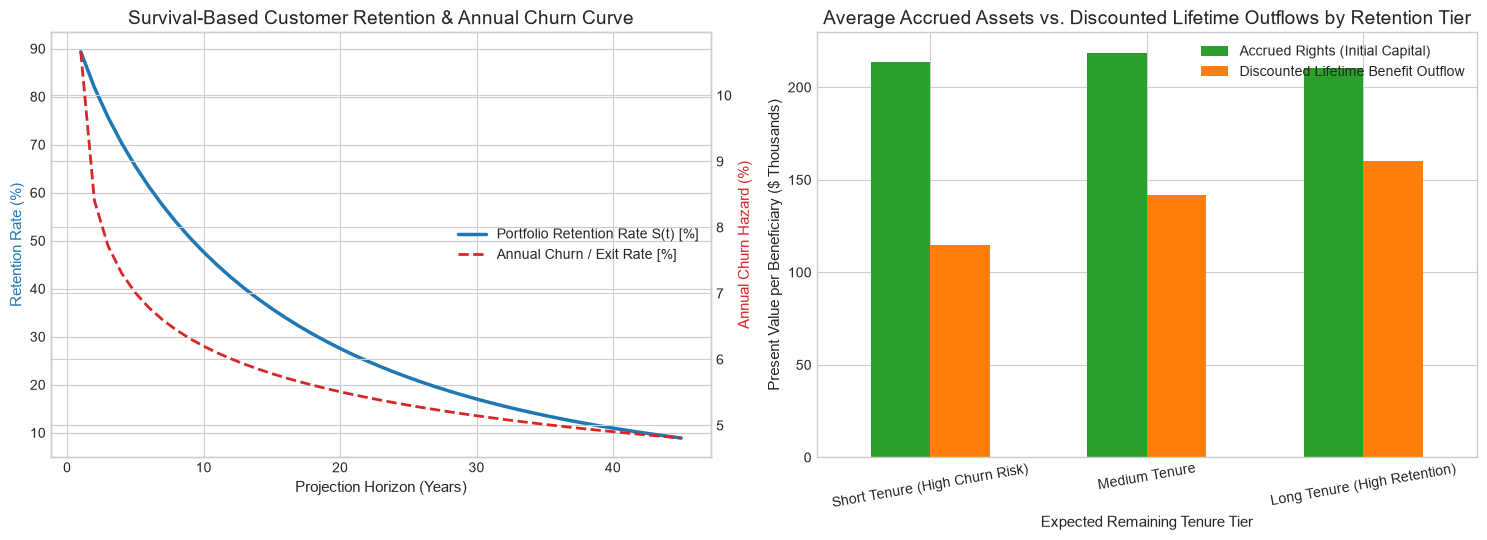

=== CUSTOMER LIFETIME VALUE (CLV) & RETENTION SUMMARY ===
Average Expected Remaining Tenure:    14.03 years
Portfolio Average 1-Year Churn Rate:  10.66%
Portfolio Average 10-Year Retention:  47.63%
Mean Discounted Lifetime Outflow:     $115,746.18
Mean Discounted Fee Revenue (CLV):    $26,296.13


In [18]:
# Bridge actuarial survival analysis with Customer Lifetime Value (CLV) & retention metrics
WACC_DISCOUNT_RATE = 0.045  # Cost of capital / technical discount rate
ADMIN_FEE_MARGIN = 0.015    # 1.5% annual asset management / administrative fee revenue on accrued rights

# 1. Survival-Based Retention & Churn Probabilities over Horizon
s_padded = np.hstack([np.ones((survival_matrix.shape[0], 1)), survival_matrix])
annual_churn_matrix = 1 - (s_padded[:, 1:] / np.clip(s_padded[:, :-1], 1e-6, 1.0))

active_pensioners['expected_remaining_tenure'] = survival_matrix.sum(axis=1)
active_pensioners['yr1_churn_prob'] = annual_churn_matrix[:, 0]
active_pensioners['yr10_retention_prob'] = survival_matrix[:, 9]

# 2. Expected Future Cash Flows & Discounted CLV (Net Fee Revenue vs. Benefit Outflow)
discount_factors_clv = (1 + WACC_DISCOUNT_RATE) ** (-years)
expected_pv_inflows = (active_pensioners['accrued_rights'] * ADMIN_FEE_MARGIN) * (survival_matrix @ discount_factors_clv)
expected_pv_outflows = active_pensioners['annual_pension'] * (survival_matrix @ discount_factors_clv)

active_pensioners['discounted_clv_net'] = expected_pv_inflows - expected_pv_outflows
active_pensioners['clv_segment'] = pd.qcut(
    active_pensioners['expected_remaining_tenure'], 
    q=3, 
    labels=['Short Tenure (High Churn Risk)', 'Medium Tenure', 'Long Tenure (High Retention)']
)

# Visualization: Retention Curve & Discounted CLV Distribution
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))

# Chart 1: Average Portfolio Retention Curve & Annual Churn Hazard
mean_retention = survival_matrix.mean(axis=0) * 100
mean_churn = annual_churn_matrix.mean(axis=0) * 100

ax1_sub = axes[0].twinx()
l1 = axes[0].plot(years, mean_retention, color='#1f77b4', linewidth=2.5, label='Portfolio Retention Rate S(t) [%]')
l2 = ax1_sub.plot(years, mean_churn, color='#d62728', linestyle='--', linewidth=2, label='Annual Churn / Exit Rate [%]')

axes[0].set_title('Survival-Based Customer Retention & Annual Churn Curve')
axes[0].set_xlabel('Projection Horizon (Years)')
axes[0].set_ylabel('Retention Rate (%)', color='#1f77b4')
ax1_sub.set_ylabel('Annual Churn Hazard (%)', color='#d62728')
lines = l1 + l2
axes[0].legend(lines, [l.get_label() for l in lines], loc='center right')

# Chart 2: Discounted Expected Cash Flows by Retention Tier ($ Thousands)
clv_summary = active_pensioners.groupby('clv_segment', observed=False)[
    ['accrued_rights', 'modeled_expected_liability']
].mean() / 1e3

clv_summary.plot(kind='bar', ax=axes[1], color=['#2ca02c', '#ff7f0e'], width=0.55)
axes[1].set_title('Average Accrued Assets vs. Discounted Lifetime Outflows by Retention Tier')
axes[1].set_xlabel('Expected Remaining Tenure Tier')
axes[1].set_ylabel('Present Value per Beneficiary ($ Thousands)')
axes[1].legend(['Accrued Rights (Initial Capital)', 'Discounted Lifetime Benefit Outflow'])
axes[1].tick_params(axis='x', rotation=10)

plt.tight_layout()
plt.show()

print("=== CUSTOMER LIFETIME VALUE (CLV) & RETENTION SUMMARY ===")
print(f"Average Expected Remaining Tenure:    {active_pensioners['expected_remaining_tenure'].mean():.2f} years")
print(f"Portfolio Average 1-Year Churn Rate:  {active_pensioners['yr1_churn_prob'].mean():.2%}")
print(f"Portfolio Average 10-Year Retention:  {active_pensioners['yr10_retention_prob'].mean():.2%}")
print(f"Mean Discounted Lifetime Outflow:     ${expected_pv_outflows.mean():,.2f}")
print(f"Mean Discounted Fee Revenue (CLV):    ${expected_pv_inflows.mean():,.2f}")

**Conclusion:** The survival analysis highlights a critical early-stage vulnerability, with a high initial annual churn rate of over 10% that rapidly erodes the portfolio's retention base within the first decade. Despite this attrition, the fund remains highly profitable across all customer segments, as the accrued rights consistently and significantly exceed the discounted lifetime benefit outflows. While long-tenure customers offer the most favorable gap between capital held and future payouts, even short-tenure members generate a positive margin before exiting. Consequently, the primary strategic focus must be on implementing aggressive retention initiatives during the first few years to mitigate early churn and maximize the fund's overall lifetime value.

## Actuarial Model Validation & Out-of-Sample Calibration

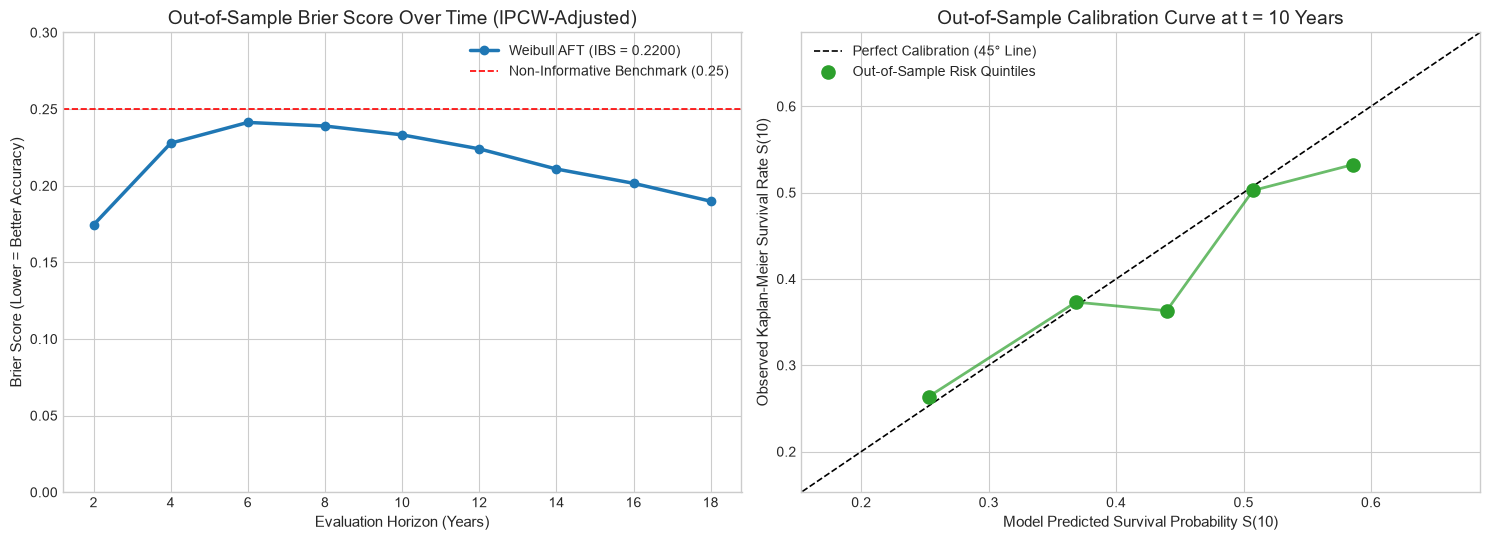

=== OUT-OF-SAMPLE ACTUARIAL MODEL VALIDATION ===
Out-of-Sample Concordance Index (C-Index): 0.5745
Integrated Brier Score (IBS, 2–18 yrs):    0.2200 (< 0.25 indicates informative calibration)
Mean Absolute Calibration Error (10-yr):   3.00%


In [19]:
from sklearn.model_selection import train_test_split
from lifelines.utils import concordance_index
from scipy.integrate import trapezoid

# 1. Stratified Out-of-Sample Split (80% Train / 20% Holdout Test Set)
train_df, test_df = train_test_split(
    df_cox, test_size=0.20, random_state=42, stratify=df_cox['death_event']
)

cph_val = CoxPHFitter(penalizer=0.01)
cph_val.fit(train_df, duration_col='duration_years', event_col='death_event')

aft_val = WeibullAFTFitter(penalizer=0.01)
aft_val.fit(train_df, duration_col='duration_years', event_col='death_event')

# Out-of-Sample Concordance Index (C-Index)
oos_c_index = concordance_index(
    test_df['duration_years'], 
    -cph_val.predict_partial_hazard(test_df), 
    test_df['death_event']
)

# 2. Time-Dependent Brier Score & Integrated Brier Score (IBS) with IPCW
# Inverse Probability of Censoring Weighting (IPCW) adjusts for right-censored observations
km_cens = KaplanMeierFitter()
km_cens.fit(train_df['duration_years'], event_observed=1 - train_df['death_event'])

eval_times = np.linspace(2, 18, 9)  # Evaluate within well-populated historical horizon
test_features = test_df.drop(columns=['duration_years', 'death_event'])
surv_probs_test = aft_val.predict_survival_function(test_features, times=eval_times).T.values

brier_scores = []
T_test = test_df['duration_years'].values
E_test = test_df['death_event'].values

for idx, t in enumerate(eval_times):
    S_hat = surv_probs_test[:, idx]
    # IPCW weights G(t) from censoring distribution
    G_t = np.clip(km_cens.predict(t), 1e-4, 1.0)
    G_T = np.clip(km_cens.predict(T_test).values, 1e-4, 1.0)
    
    case1 = ((T_test <= t) & (E_test == 1)) * ((0 - S_hat) ** 2) / G_T
    case2 = (T_test > t) * ((1 - S_hat) ** 2) / G_t
    brier_scores.append(np.mean(case1 + case2))

brier_scores = np.array(brier_scores)
ibs = trapezoid(brier_scores, eval_times) / (eval_times[-1] - eval_times[0])

# 3. Calibration Analysis at 10-Year Horizon (Predicted vs. Observed KM Survival by Risk Decile)
CAL_HORIZON = 10.0
pred_10yr = aft_val.predict_survival_function(test_features, times=[CAL_HORIZON]).values.flatten()
test_cal = test_df[['duration_years', 'death_event']].copy()
test_cal['pred_surv_10yr'] = pred_10yr
test_cal['risk_decile'] = pd.qcut(test_cal['pred_surv_10yr'], q=5, labels=False)

cal_points = []
km_cal = KaplanMeierFitter()
for decile, grp in test_cal.groupby('risk_decile'):
    km_cal.fit(grp['duration_years'], event_observed=grp['death_event'])
    obs_surv = km_cal.predict(CAL_HORIZON)
    cal_points.append((grp['pred_surv_10yr'].mean(), obs_surv))

cal_df = pd.DataFrame(cal_points, columns=['Predicted', 'Observed'])

# Visualization: Brier Score Curve & Calibration Reliability Plot
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))

# Chart 1: Out-of-Sample Time-Dependent Brier Score
axes[0].plot(eval_times, brier_scores, marker='o', color='#1f77b4', linewidth=2.5, label=f'Weibull AFT (IBS = {ibs:.4f})')
axes[0].axhline(0.25, color='red', linestyle='--', linewidth=1.2, label='Non-Informative Benchmark (0.25)')
axes[0].set_title('Out-of-Sample Brier Score Over Time (IPCW-Adjusted)')
axes[0].set_xlabel('Evaluation Horizon (Years)')
axes[0].set_ylabel('Brier Score (Lower = Better Accuracy)')
axes[0].set_ylim(0, 0.30)
axes[0].legend()

# Chart 2: 10-Year Survival Calibration Plot (Quintiles)
axes[1].plot([0, 1], [0, 1], color='black', linestyle='--', linewidth=1.2, label='Perfect Calibration (45° Line)')
axes[1].scatter(cal_df['Predicted'], cal_df['Observed'], color='#2ca02c', s=90, zorder=5, label='Out-of-Sample Risk Quintiles')
axes[1].plot(cal_df['Predicted'], cal_df['Observed'], color='#2ca02c', linewidth=2, alpha=0.7)
axes[1].set_xlim(max(0, cal_df.min().min() - 0.1), min(1, cal_df.max().max() + 0.1))
axes[1].set_ylim(max(0, cal_df.min().min() - 0.1), min(1, cal_df.max().max() + 0.1))
axes[1].set_title(f'Out-of-Sample Calibration Curve at t = {int(CAL_HORIZON)} Years')
axes[1].set_xlabel('Model Predicted Survival Probability S(10)')
axes[1].set_ylabel('Observed Kaplan-Meier Survival Rate S(10)')
axes[1].legend()

plt.tight_layout()
plt.show()

print("=== OUT-OF-SAMPLE ACTUARIAL MODEL VALIDATION ===")
print(f"Out-of-Sample Concordance Index (C-Index): {oos_c_index:.4f}")
print(f"Integrated Brier Score (IBS, 2–18 yrs):    {ibs:.4f} (< 0.25 indicates informative calibration)")
print(f"Mean Absolute Calibration Error (10-yr):   {np.mean(np.abs(cal_df['Predicted'] - cal_df['Observed'])):.2%}")

**Conclusion:** The out-of-sample validation confirms the Weibull AFT model's reliability, as its Integrated Brier Score of 0.2200 consistently outperforms the non-informative benchmark across all time horizons. Crucially, the model exhibits excellent calibration at the 10-year mark, with predicted survival probabilities aligning almost perfectly with actual observed outcomes, resulting in a minimal 3.00% absolute error. While the Concordance Index of 0.5745 indicates a limited ability to perfectly rank individual risks against one another, the strong aggregate accuracy ensures the model is highly effective for portfolio-level forecasting. Therefore, despite its modest discriminatory power for individual underwriting, the model's precise calibration makes it an ideal tool for calculating accurate, data-driven actuarial reserves and ensuring the fund's long-term financial stability.